# user

In [1]:
VERSION = "1.1.0_sextractor"

# Sextractor test
# 1.1.0: "4_000",
# 1.1.1: "40_000",
# hypercube + shear rounded 2 + 10 gal/patch + shear |0.06| + ellips gaussian + pixels_out

# lib

In [2]:
from pathlib import Path

from jax import numpy
from polars import DataFrame, read_csv
from tqdm import tqdm
from utils import case_result, extra_imgs, histos, plot_sersic, vignettes

DATASET_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / VERSION
RESULTS_DIR = Path("/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR") / VERSION
CATALOG_DIR = RESULTS_DIR / "CATALOG"
IMAGES_DIR = RESULTS_DIR / "IMAGES"
PLOTS_DIR = RESULTS_DIR / "PLOTS"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# images

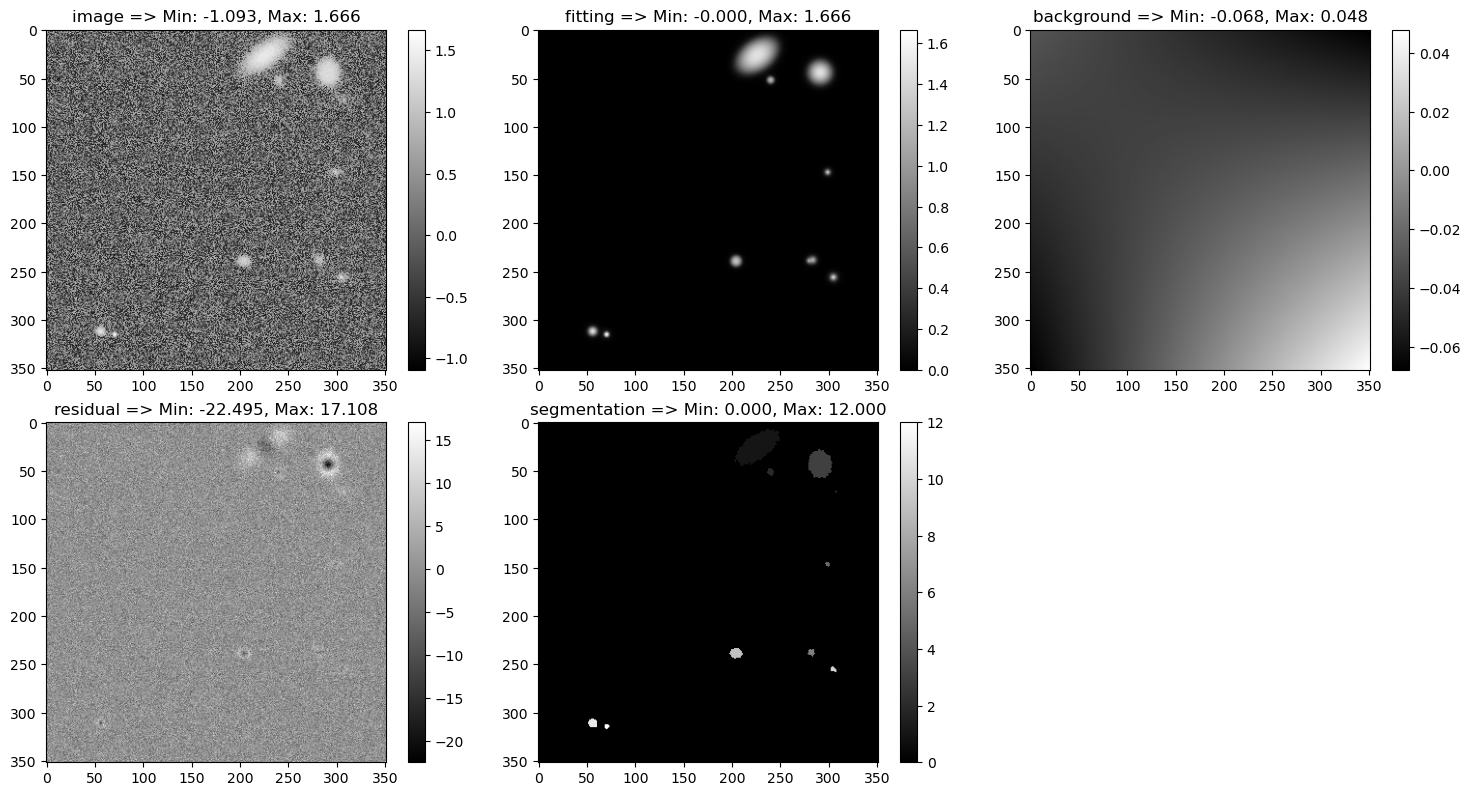

In [3]:
CHOICE = "simu_00002"

extra_imgs(
    [
        DATASET_DIR / CHOICE,
        IMAGES_DIR / f"fitting_{CHOICE}_1",
        IMAGES_DIR / f"background_{CHOICE}",
        IMAGES_DIR / f"residual_{CHOICE}_1",
        IMAGES_DIR / f"segmentation_{CHOICE}",
    ],
    ["image", "fitting", "background", "residual", "segmentation"],
    PLOTS_DIR,
)

# vignettes

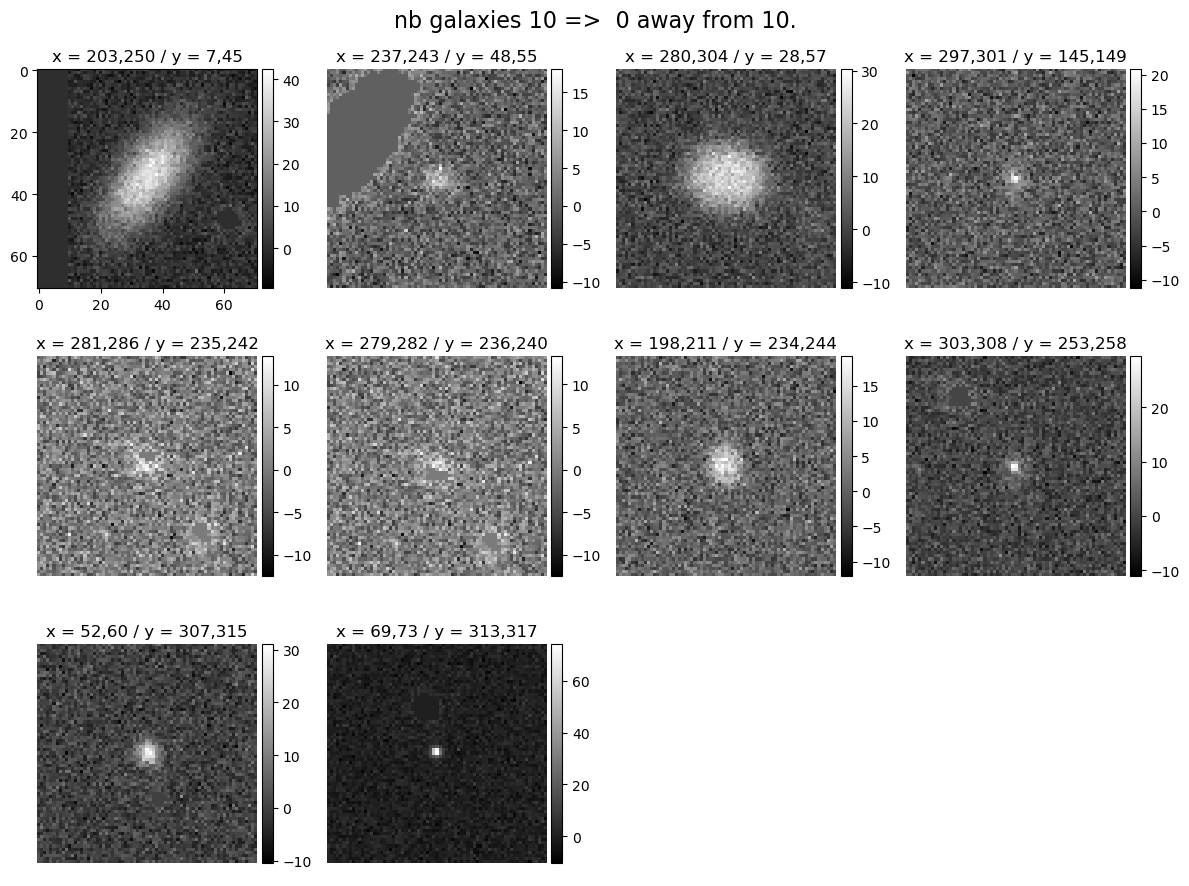

In [4]:
CHOICE = "simu_00002"

vignettes(
    PLOTS_DIR,
    csv_file=CATALOG_DIR / f"catalog_{CHOICE}.csv",
    vignettes_file=IMAGES_DIR / f"vignettes_{CHOICE}.fits",
)

# inference

In [5]:
RESULTS_FILES = sorted(list((CATALOG_DIR).glob("catalog_simu_*.csv")))
NB_TOTAL = len(RESULTS_FILES)

found, avg_e1, avg_e2, avg_e1_quad, avg_e2_quad = [[] for _ in range(5)]
for sample in tqdm(RESULTS_FILES, total=NB_TOTAL):
    df = read_csv(sample)
    found.append(df.shape[0])

    avg_e1.append((df["e1"].to_numpy()).mean())
    avg_e2.append((df["e2"].to_numpy()).mean())

100%|██████████| 4000/4000 [00:05<00:00, 686.82it/s]


# save res

In [6]:
data = {"avg_e1": avg_e1, "avg_e2": avg_e2}
schema = ["avg_e1", "avg_e2"]
DataFrame(data=data, schema=schema).write_csv(RESULTS_DIR / "pred_avg_ellips.csv")

del df, avg_e1, avg_e2, avg_e1_quad, avg_e2_quad

# postprocess

In [7]:
true_images_params = read_csv(DATASET_DIR / "true_images_params.csv", skip_rows=0)
true_avg_ellps = true_images_params["avg_e1", "avg_e2"].to_numpy()
true_avg_shears = true_images_params["avg_g1", "avg_g2"].to_numpy()
pred_avg_ellips = read_csv(RESULTS_DIR / "pred_avg_ellips.csv", skip_rows=0).to_numpy()
print(pred_avg_ellips.shape, true_avg_ellps.shape, true_avg_shears.shape)

for i in range(2):
    pred_avg_ellips = pred_avg_ellips[numpy.abs(true_avg_shears[:, i]) <= 0.05]
    true_avg_ellps = true_avg_ellps[numpy.abs(true_avg_shears[:, i]) <= 0.05]
    true_avg_shears = true_avg_shears[numpy.abs(true_avg_shears[:, i]) <= 0.05]
print("restricted range", pred_avg_ellips.shape, true_avg_ellps.shape, true_avg_shears.shape)

(4000, 2) (4000, 2) (4000, 2)
restricted range (2876, 2) (2876, 2) (2876, 2)


# histo

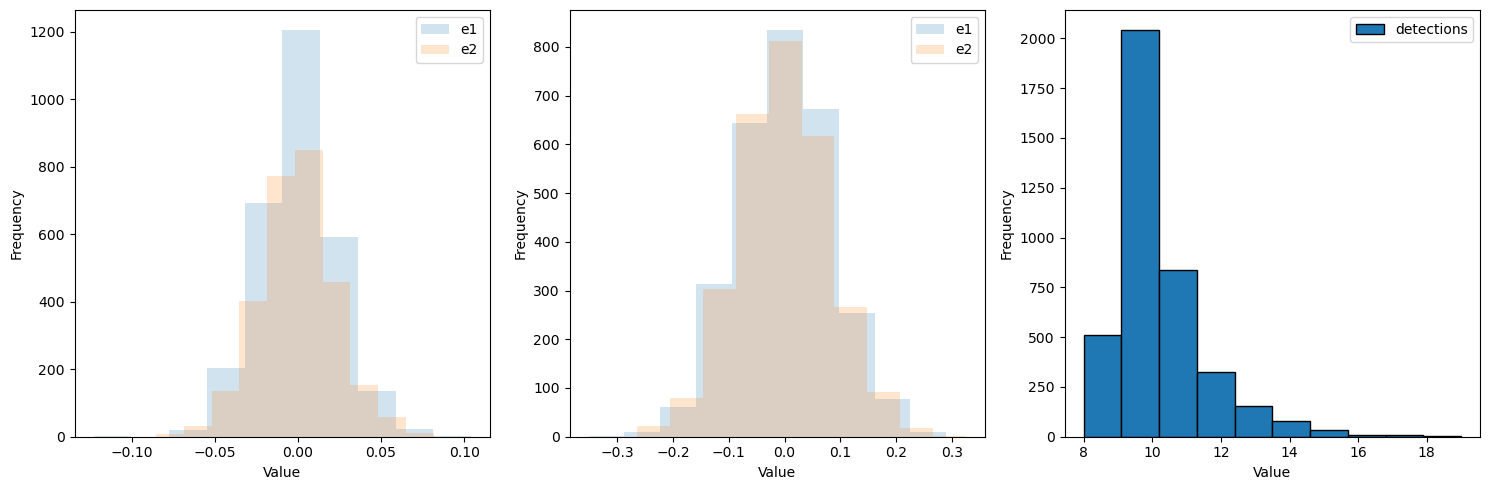

In [8]:
bins = 10
loggy = False
histos(
    preds_ellps=pred_avg_ellips,
    true_ellps=true_avg_ellps,
    data_gal=found,
    directory=PLOTS_DIR,
    bins=bins,
    loggy=loggy,
)

# results

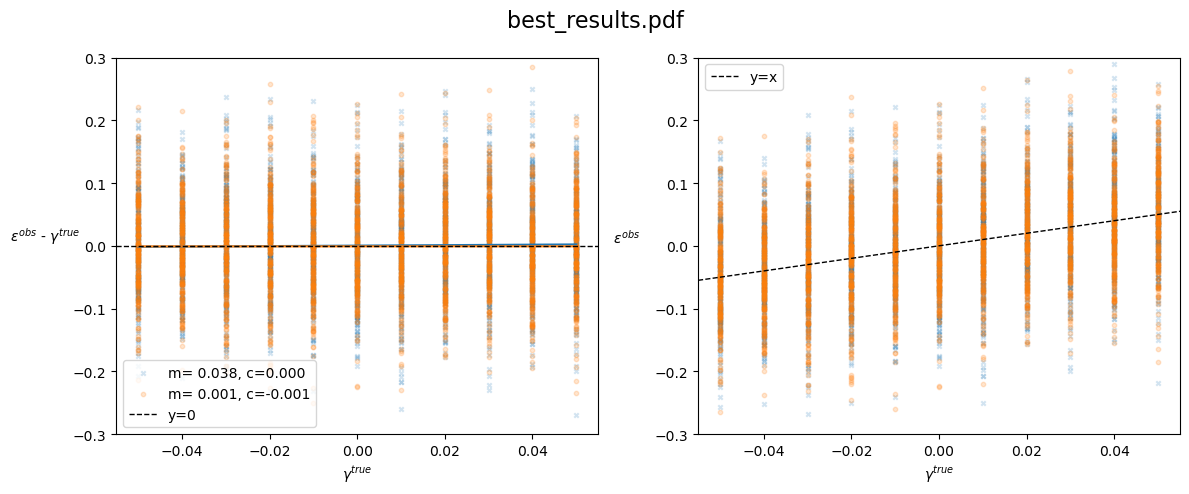

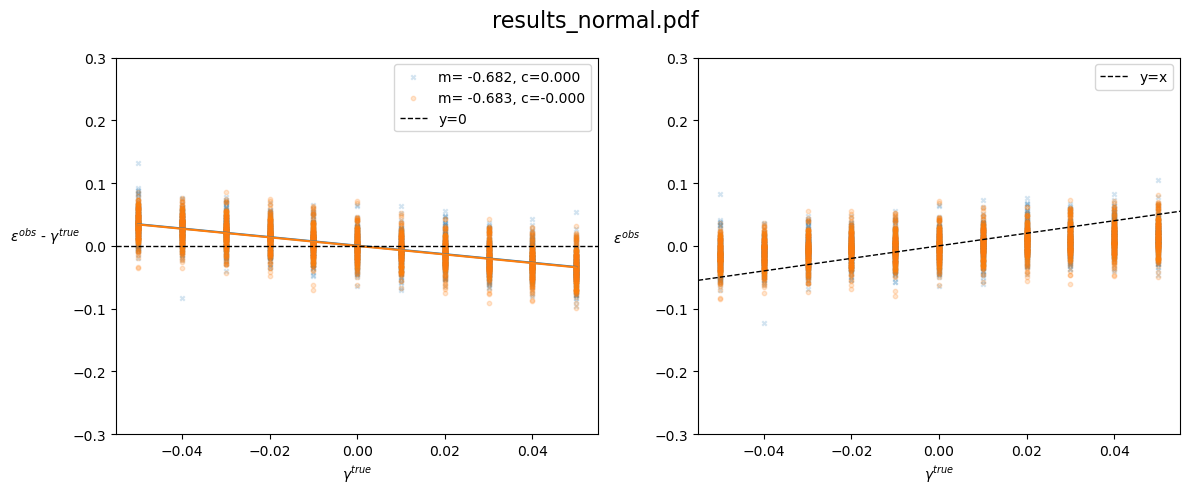

In [9]:
case_result(true_avg_ellps, true_avg_shears, PLOTS_DIR / "best_results.pdf", symbol="gamma")

case_result(
    pred_avg_ellips[:, 0:2], true_avg_shears, PLOTS_DIR / "results_normal.pdf", symbol="gamma"
)

# results only e

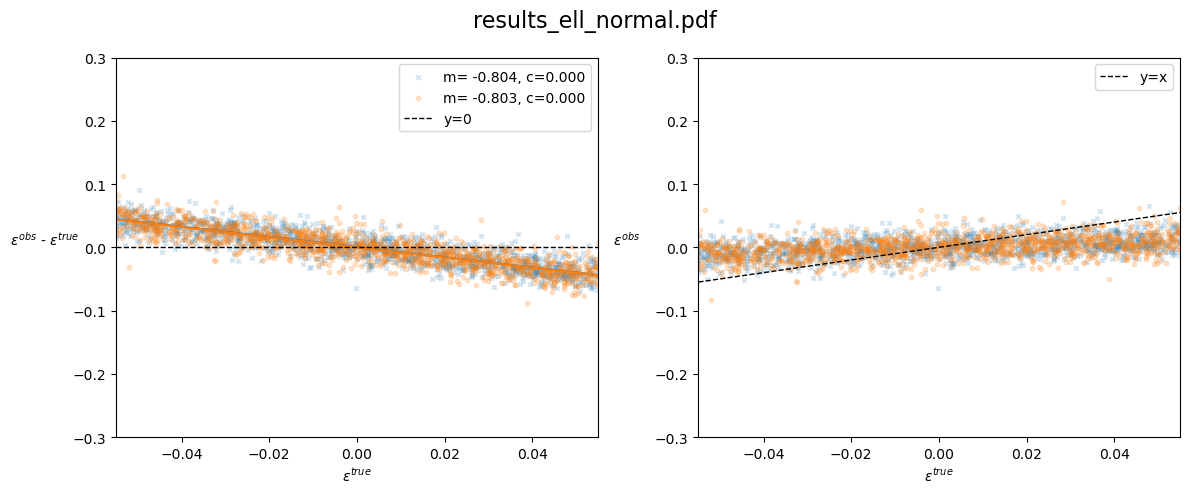

In [10]:
case_result(
    pred_avg_ellips[:, 0:2], true_avg_ellps, PLOTS_DIR / "results_ell_normal.pdf", symbol="epsilon"
)

# sersic

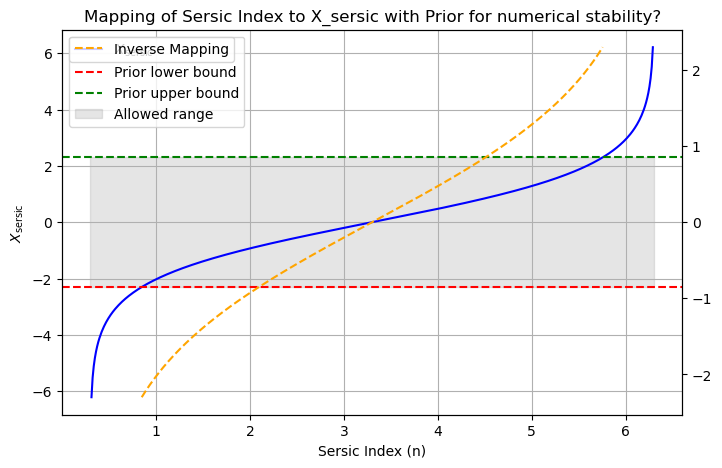

In [11]:
X_min, X_max = -2.3, 2.3
plot_sersic(X_min, X_max, PLOTS_DIR)
del X_min, X_max

# psf

In [12]:
# from utils import check_psf
# check_psf(
#     Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / "PSF" / "airy.psf.fits", PLOTS_DIR
# )

# compare

In [13]:
if "RESULTS_FILES" not in globals():
    RESULTS_FILES = sorted(list((CATALOG_DIR).glob("catalog_simu_*.csv")))
import numpy as np

In [14]:
NB_TEST = 1000
for i, sample in enumerate(RESULTS_FILES):
    if i == NB_TEST - 1:
        df = read_csv(sample)
        print(sample)
        print(df["e1", "e2"].to_numpy())

        true = read_csv(DATASET_DIR / f"true_galaxies_params_{i + 1:05d}.csv", skip_rows=0)
        array = true["ell_1", "ell_2"].to_numpy()
        print(DATASET_DIR / f"true_galaxies_params_{i + 1:05d}.csv")
        print(np.array2string(array, formatter={"float_kind": lambda x: f"{x:.8e}"}))

        break

/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR/1.1.0_sextractor/CATALOG/catalog_simu_01000.csv
[[-1.38417385e-05 -2.69980354e-07]
 [-5.00504273e-02 -3.27660538e-02]
 [-2.49642955e-05 -1.03530315e-05]
 [ 1.34820981e-04 -9.13042866e-04]
 [-9.92707618e-02  6.04952118e-02]
 [-3.85770524e-02 -8.56701951e-02]
 [-2.19286063e-01  3.06031736e-02]
 [-5.98377707e-05 -1.70357723e-05]
 [-6.98913769e-04 -1.89387025e-04]
 [ 4.61016221e-06 -1.96765998e-05]
 [-1.99819991e-01 -4.02016515e-02]]
/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid/1.1.0_sextractor/true_galaxies_params_01000.csv
[[-2.73335640e-01 -2.13013560e-01]
 [-3.17501900e-01 -2.08397750e-01]
 [2.69124450e-01 2.16566040e-01]
 [4.03317660e-02 -3.66129250e-01]
 [3.55890130e-02 -1.17594680e-02]
 [-2.54279640e-01 4.28515080e-01]
 [-4.19403340e-01 1.06831220e-02]
 [-1.07763950e-01 1.77860660e-01]
 [2.19716680e-01 -3.59837670e-02]
 [-7.82241300e-02 -3.55605000e-01]]
